In [2]:
library(readr)
library(dplyr)
library(psych)
library(lubridate)
library(ggplot2)
library(sf)
library(maps)
library(corrplot)
library(writexl)
library(pROC)
library(keras)
library(praznik)
library(infotheo)
library(Information)
library(geosphere)
library(leaflet)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union



Attaching package: ‘ggplot2’


The following objects are masked from ‘package:psych’:

    %+%, alpha


Linking to GEOS 3.10.2, GDAL 3.4.1, PROJ 8.2.1; sf_use_s2() is TRUE

corrplot 0.95 loaded



In [3]:
df <- read.csv2("/kaggle/input/datasets/elizaskorik/cards-brah/full_data (1).csv", stringsAsFactors = FALSE)
head(df, 10)

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,⋯,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>
1,2020-06-21 12:14:25,2.291164e+15,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,Columbia,⋯,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
2,2020-06-21 12:14:33,3.573030e+15,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,Altonah,⋯,40.3207,-110.436,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450497999999996,-109.960431,0
3,2020-06-21 12:14:53,3.598215e+15,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,Bellmore,⋯,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.49581,-74.196111,0
4,2020-06-21 12:15:15,3.591920e+15,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,Titusville,⋯,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812397999999998,-80.883061,0
5,2020-06-21 12:15:17,3.526826e+15,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,Falmouth,⋯,44.2529,-85.01700000000001,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0
6,2020-06-21 12:15:37,3.040768e+13,fraud_Daugherty LLC,kids_pets,19.55,Danielle,Evans,F,76752 David Lodge Apt. 064,Breesport,⋯,42.1939,-76.7361,520,Psychotherapist,1991-10-13,798db04aaceb4febd084f1a7c404da93,1371816937,41.747157,-77.584197,0
7,2020-06-21 12:15:44,2.131807e+14,fraud_Romaguera Ltd,health_fitness,133.93,Kayla,Sutton,F,010 Weaver Land,Carlotta,⋯,40.507,-123.9743,1139,"Therapist, occupational",1951-01-15,17003d7ce534440eadb10c4750e020e5,1371816944,41.499458000000004,-124.888729,0
8,2020-06-21 12:15:50,3.589290e+15,fraud_Reichel LLC,personal_care,10.37,Paula,Estrada,F,350 Stacy Glens,Spencer,⋯,43.7557,-97.5936,343,"Development worker, international aid",1972-03-05,8be473af4f05fc6146ea55ace73e7ca2,1371816950,44.495498,-97.728453,0
9,2020-06-21 12:16:10,3.596357e+15,"fraud_Goyette, Howell and Collier",shopping_pos,4.37,David,Everett,M,4138 David Fall,Morrisdale,⋯,41.0001,-78.2357,3688,Advice worker,1973-05-27,71a1da150d1ce510193d7622e08e784e,1371816970,41.546067,-78.120238,0


In [4]:
cat("Количество дубликатов: ", sum(duplicated(df)), "\n")
cat("Количество пропусков: ",sum(is.na(df)), "\n")

Количество дубликатов:  0 
Количество пропусков:  0 


In [5]:
df$amt <- as.numeric(df$amt)
df$lat <- as.numeric(df$lat)
df$long <- as.numeric(df$long)
df$city_pop <- as.numeric(df$city_pop)
df$merch_lat <- as.numeric(df$merch_lat)
df$merch_long <- as.numeric(df$merch_long)
df$long <- as.numeric(df$long)
df$trans_date_trans_time <- as.POSIXct(df$trans_date_trans_time)
df$dob <- as.Date(df$dob)
df$cc_num <- as.character(df$cc_num)
df$zip <- as.character(df$zip)
df$category <- as.factor(df$category)
df$state <- as.factor(df$state)
df$gender <- as.factor(df$gender)
head(df, 10)

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,⋯,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
,<dttm>,<chr>,<chr>,<fct>,<dbl>,<chr>,<chr>,<fct>,<chr>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<chr>,<date>,<chr>,<int>,<dbl>,<dbl>,<int>
1,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,Columbia,⋯,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.98639,-81.20071,0
2,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,Altonah,⋯,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.45050,-109.96043,0
3,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,Bellmore,⋯,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.49581,-74.19611,0
4,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,Titusville,⋯,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.81240,-80.88306,0
5,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,Falmouth,⋯,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.95915,-85.88473,0
6,2020-06-21 12:15:37,30407675418785,fraud_Daugherty LLC,kids_pets,19.55,Danielle,Evans,F,76752 David Lodge Apt. 064,Breesport,⋯,42.1939,-76.7361,520,Psychotherapist,1991-10-13,798db04aaceb4febd084f1a7c404da93,1371816937,41.74716,-77.58420,0
7,2020-06-21 12:15:44,213180742685905,fraud_Romaguera Ltd,health_fitness,133.93,Kayla,Sutton,F,010 Weaver Land,Carlotta,⋯,40.5070,-123.9743,1139,"Therapist, occupational",1951-01-15,17003d7ce534440eadb10c4750e020e5,1371816944,41.49946,-124.88873,0
8,2020-06-21 12:15:50,3589289942931264,fraud_Reichel LLC,personal_care,10.37,Paula,Estrada,F,350 Stacy Glens,Spencer,⋯,43.7557,-97.5936,343,"Development worker, international aid",1972-03-05,8be473af4f05fc6146ea55ace73e7ca2,1371816950,44.49550,-97.72845,0
9,2020-06-21 12:16:10,3596357274378601,"fraud_Goyette, Howell and Collier",shopping_pos,4.37,David,Everett,M,4138 David Fall,Morrisdale,⋯,41.0001,-78.2357,3688,Advice worker,1973-05-27,71a1da150d1ce510193d7622e08e784e,1371816970,41.54607,-78.12024,0


In [6]:
cat("Ошибка в широте клиента: ", any(df$lat < -90 | df$lat > 90), "\n")
cat("Ошибка в широте торговой точке: ", any(df$merch_lat < -90 | df$merch_lat > 90), "\n")
cat("Ошибка в долготе клиента: ", any(df$long < -180 | df$long > 180), "\n")
cat("Ошибка в долготе торговой точке: ", any(df$merch_long < -180 | df$merch_long > 180), "\n")
cat("Ошибка в сумме: ", any(df$amt <= 0), "\n")

Ошибка в широте клиента:  FALSE 
Ошибка в широте торговой точке:  FALSE 
Ошибка в долготе клиента:  FALSE 
Ошибка в долготе торговой точке:  FALSE 
Ошибка в сумме:  FALSE 


In [7]:
df$month <- month(df$trans_date_trans_time)
df$day_of_week <- wday(df$trans_date_trans_time, label = FALSE, week_start = 1)
df$hour <- hour(df$trans_date_trans_time)
df$age <- interval(df$dob, df$trans_date_trans_time) %/% years(1)
df$purchase_dist <- 2 * 6371.032 * asin(((sin((df$merch_lat * pi / 180 - df$lat * pi / 180) / 2))^2 + cos(df$lat * pi / 180) * cos(df$merch_lat * pi / 180) * (sin((df$merch_long * pi / 180 - df$long * pi / 180) / 2))^2)^0.5)
head(df, 10)

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,⋯,trans_num,unix_time,merch_lat,merch_long,is_fraud,month,day_of_week,hour,age,purchase_dist
,<dttm>,<chr>,<chr>,<fct>,<dbl>,<chr>,<chr>,<fct>,<chr>,<chr>,⋯,<chr>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>
1,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,Columbia,⋯,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.98639,-81.20071,0,6,7,12,52,24.56159
2,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,Altonah,⋯,324cc204407e99f51b0d6ca0055005e7,1371816873,39.45050,-109.96043,0,6,7,12,30,104.92562
3,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,Bellmore,⋯,c81755dbbbea9d5c77f094348a7579be,1371816893,40.49581,-74.19611,0,6,7,12,49,59.08037
4,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,Titusville,⋯,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.81240,-80.88306,0,6,7,12,32,27.69871
5,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,Falmouth,⋯,57ff021bd3f328f8738bb535c302a31b,1371816917,44.95915,-85.88473,0,6,7,12,64,104.33563
6,2020-06-21 12:15:37,30407675418785,fraud_Daugherty LLC,kids_pets,19.55,Danielle,Evans,F,76752 David Lodge Apt. 064,Breesport,⋯,798db04aaceb4febd084f1a7c404da93,1371816937,41.74716,-77.58420,0,6,7,12,28,85.92781
7,2020-06-21 12:15:44,213180742685905,fraud_Romaguera Ltd,health_fitness,133.93,Kayla,Sutton,F,010 Weaver Land,Carlotta,⋯,17003d7ce534440eadb10c4750e020e5,1371816944,41.49946,-124.88873,0,6,7,12,69,134.41138
8,2020-06-21 12:15:50,3589289942931264,fraud_Reichel LLC,personal_care,10.37,Paula,Estrada,F,350 Stacy Glens,Spencer,⋯,8be473af4f05fc6146ea55ace73e7ca2,1371816950,44.49550,-97.72845,0,6,7,12,48,82.96336
9,2020-06-21 12:16:10,3596357274378601,"fraud_Goyette, Howell and Collier",shopping_pos,4.37,David,Everett,M,4138 David Fall,Morrisdale,⋯,71a1da150d1ce510193d7622e08e784e,1371816970,41.54607,-78.12024,0,6,7,12,47,61.47112


In [8]:
columns_to_export <- c("merchant", "category", "gender", "month", "day_of_week", 
                       "hour", "age", "purchase_dist", "state", "city_pop", "is_fraud")

data_to_export <- df[, columns_to_export]

n <- nrow(data_to_export)
split_point <- ceiling(n / 2)

first_half <- data_to_export[1:split_point, ]
second_half <- data_to_export[(split_point + 1):n, ]

write_xlsx(first_half, "filtered_data_part1.xlsx")
write_xlsx(second_half, "filtered_data_part2.xlsx")

In [9]:
cat("Ошибка в возрасте: ", any(df$age < 5 | df$age > 110), "\n")

Ошибка в возрасте:  FALSE 


In [10]:
counts <- table(df$is_fraud)
print(counts)

proportions <- prop.table(counts) * 100
print(proportions)



      0       1 
1596143    8151 

        0         1 
99.491926  0.508074 


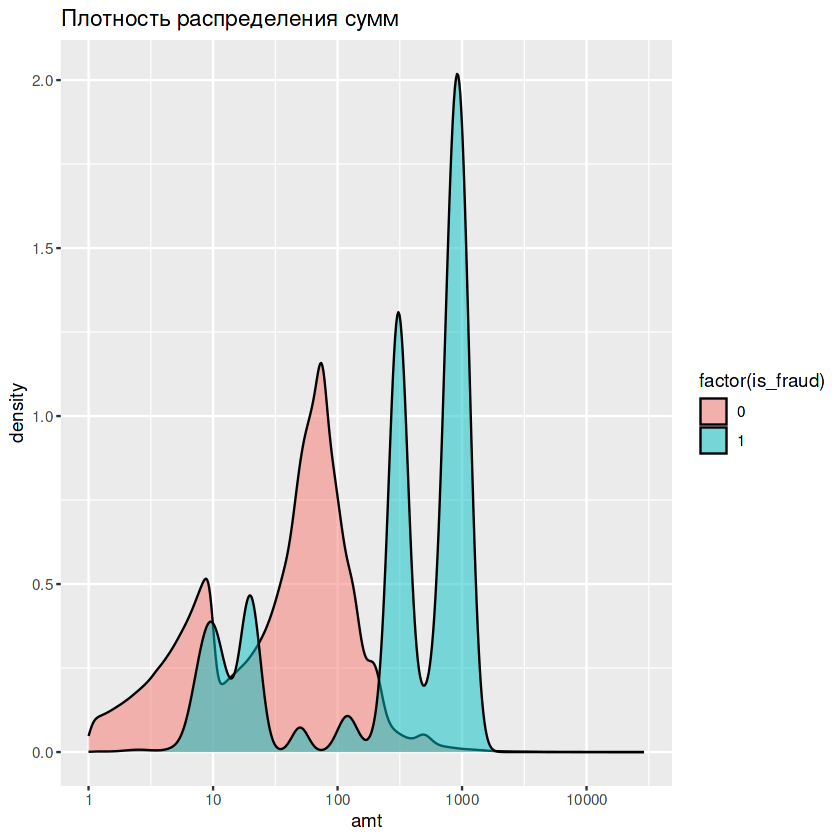

In [11]:
ggplot(df, aes(x = amt, fill = factor(is_fraud))) +
  geom_density(alpha = 0.5) +
  scale_x_log10() +
  labs(title = "Плотность распределения сумм")

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


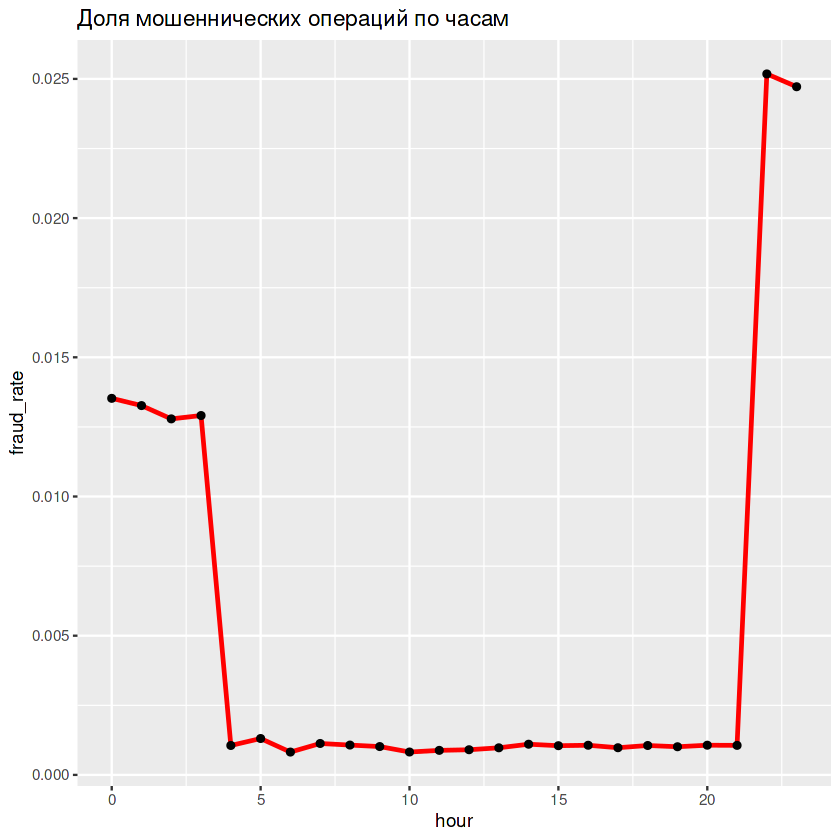

In [12]:
df %>%
  group_by(hour) %>%
  summarise(fraud_rate = mean(is_fraud)) %>%
  ggplot(aes(x = hour, y = fraud_rate)) +
  geom_line(color = "red", size = 1) +
  geom_point() +
  labs(title = "Доля мошеннических операций по часам")

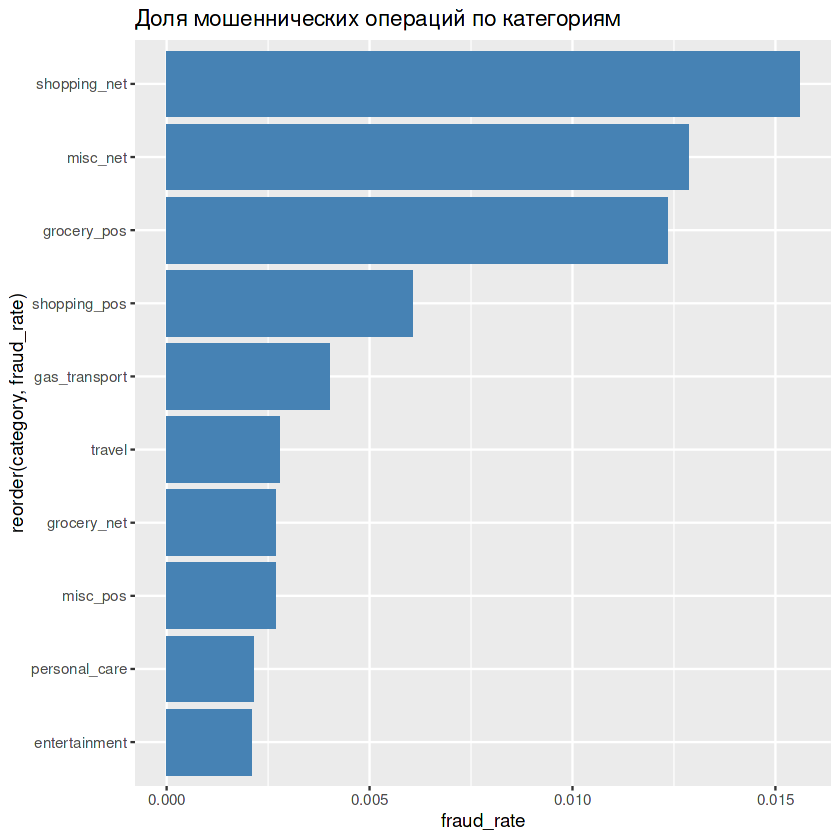

In [13]:
df %>%
  group_by(category) %>%
  summarise(fraud_rate = mean(is_fraud)) %>%
  arrange(desc(fraud_rate)) %>%
  head(10) %>%
  ggplot(aes(x = reorder(category, fraud_rate), y = fraud_rate)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(title = "Доля мошеннических операций по категориям")

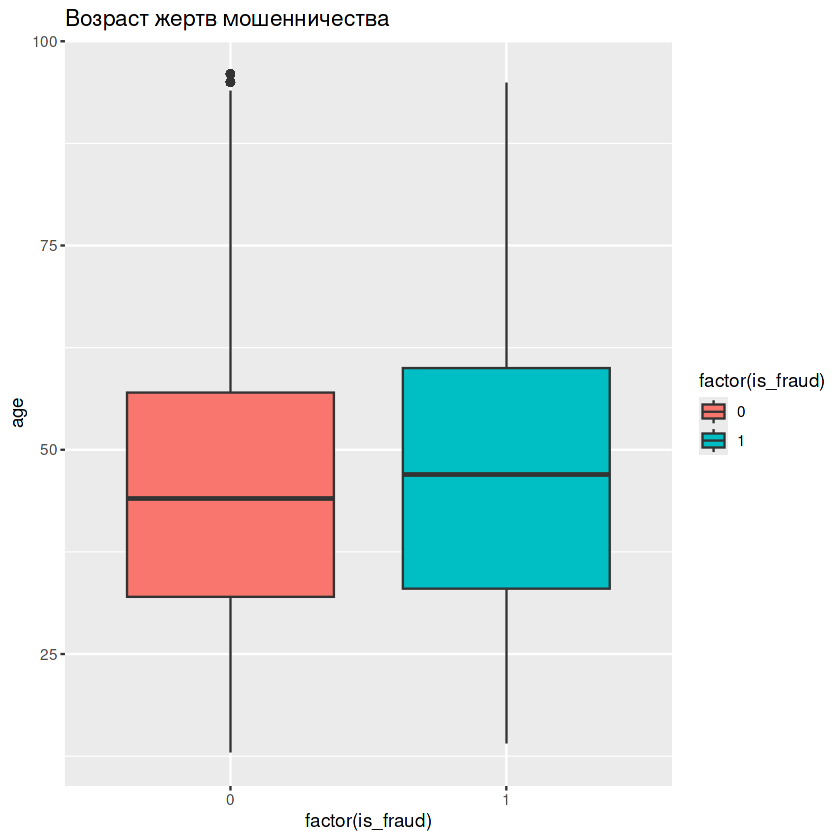

In [14]:
ggplot(df, aes(x = factor(is_fraud), y = age, fill = factor(is_fraud))) +
  geom_boxplot() +
  labs(title = "Возраст жертв мошенничества")


In [15]:
fraud_data <- df[df$is_fraud == 1, ]
leaflet(fraud_data) %>%
  addTiles() %>%
  addMarkers(
    lng = ~merch_long, lat = ~merch_lat, 
    clusterOptions = markerClusterOptions(),
    popup = ~paste("Сумма:", amt)
  )


HTML widgets cannot be represented in plain text (need html)

Warning message:
“The dot-dot notation (`..level..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(level)` instead.”


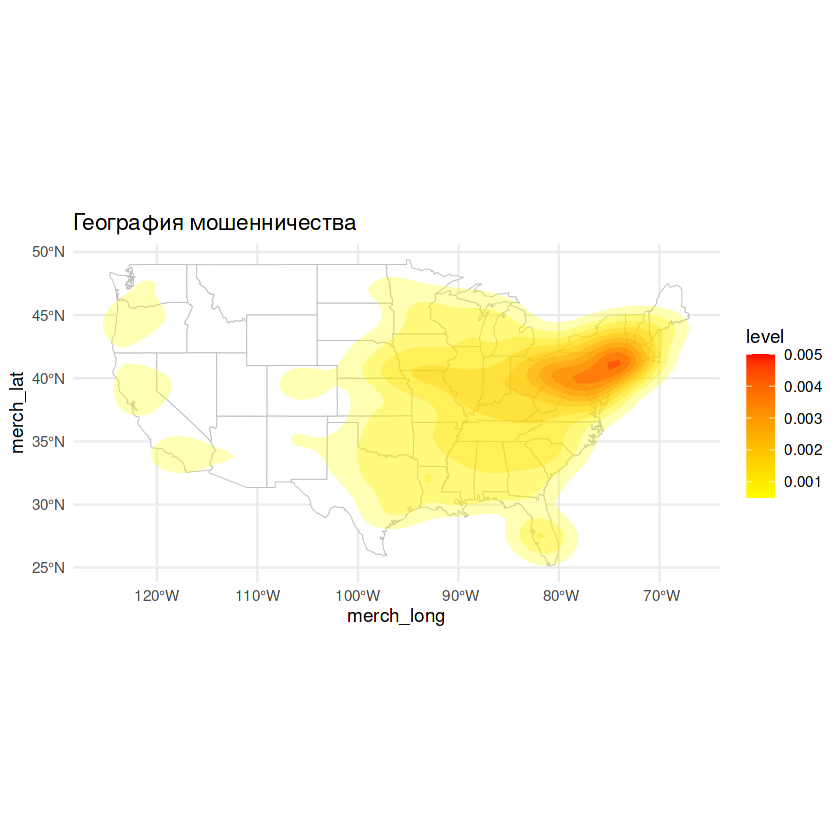

In [16]:
usa <- st_as_sf(map("state", plot = FALSE, fill = TRUE))
ggplot() +
  geom_sf(data = usa, fill = "white", color = "grey") +
  stat_density_2d(data = fraud_data, 
                  aes(x = merch_long, y = merch_lat, fill = ..level..), 
                  geom = "polygon", alpha = 0.3) +
  scale_fill_gradient(low = "yellow", high = "red") +
  theme_minimal() +
  labs(title = "География мошенничества")


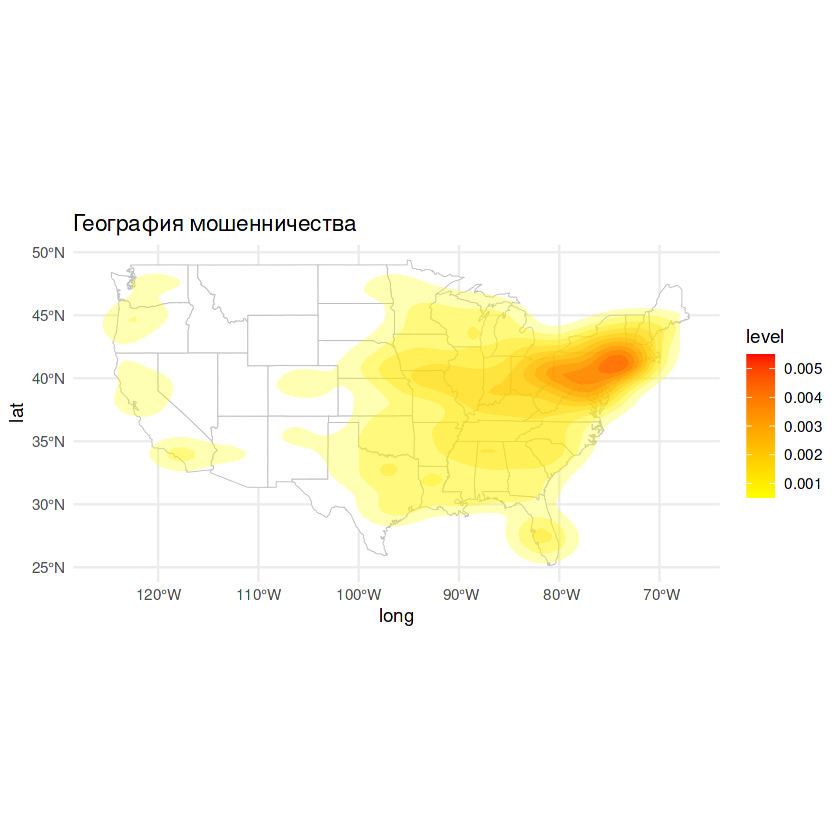

In [17]:
usa <- st_as_sf(map("state", plot = FALSE, fill = TRUE))
ggplot() +
  geom_sf(data = usa, fill = "white", color = "grey") +
  stat_density_2d(data = fraud_data, 
                  aes(x = long, y = lat, fill = ..level..), 
                  geom = "polygon", alpha = 0.3) +
  scale_fill_gradient(low = "yellow", high = "red") +
  theme_minimal() +
  labs(title = "География мошенничества")


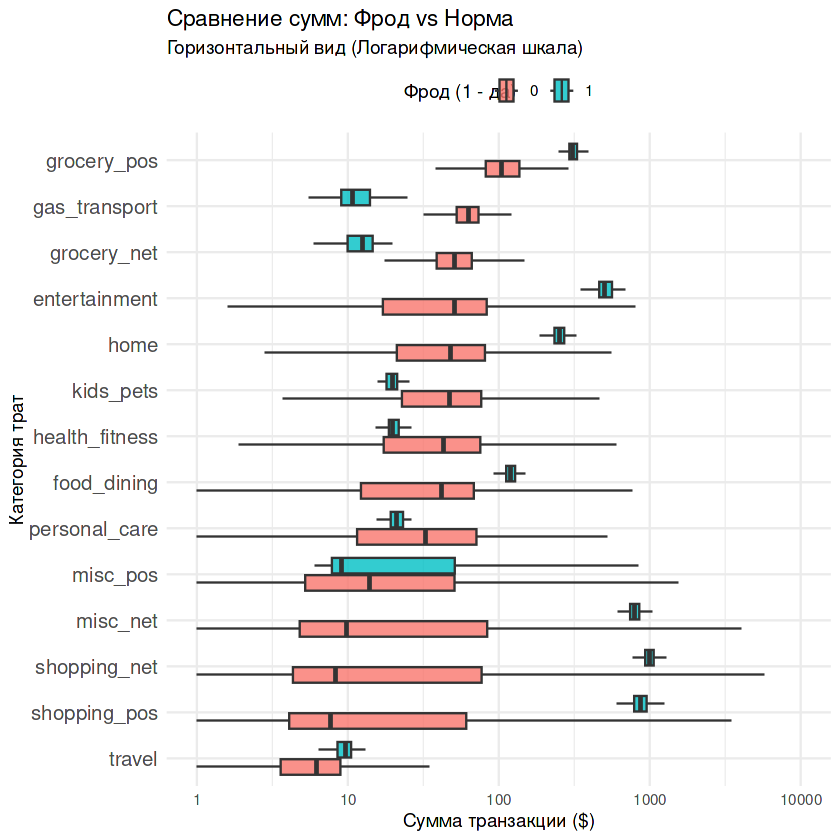

In [19]:
ggplot(df, aes(x = amt, y = reorder(category, amt, median), fill = factor(is_fraud))) +
  geom_boxplot(outlier.shape = NA, alpha = 0.8) + 
  scale_x_log10() + 
  coord_cartesian(xlim = c(1, 10000)) +
  labs(
    title = "Сравнение сумм: Фрод vs Норма",
    subtitle = "Горизонтальный вид (Логарифмическая шкала)",
    x = "Сумма транзакции ($)",
    y = "Категория трат",
    fill = "Фрод (1 - да)"
  ) +
  theme_minimal() +
  theme(
    axis.text.y = element_text(size = 12),
    legend.position = "top"
  )


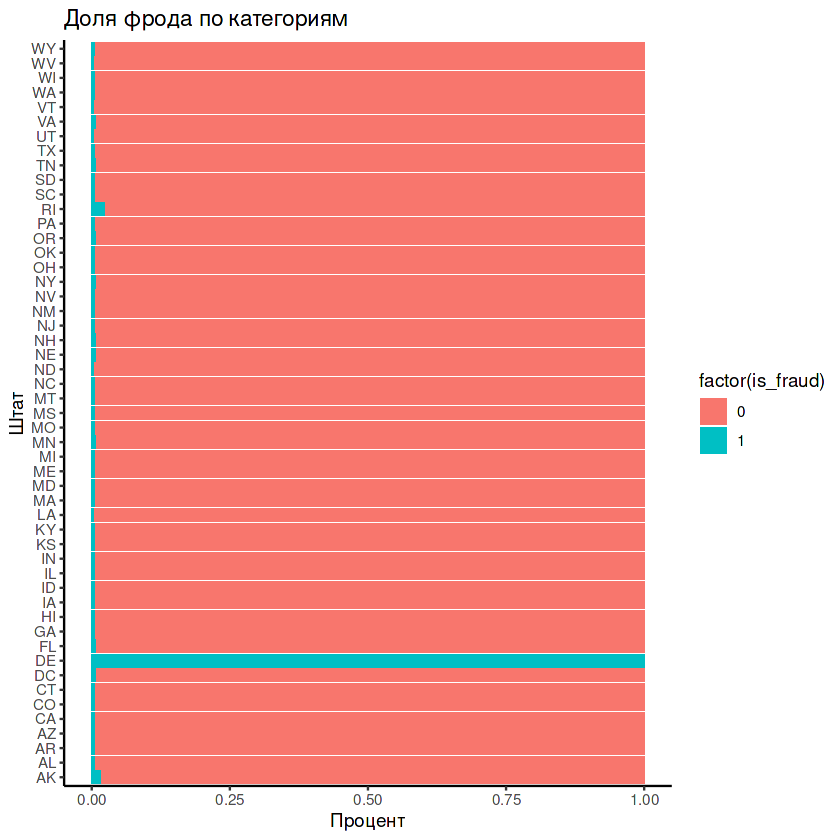

In [20]:
ggplot(df, aes(x = state, fill = factor(is_fraud))) +
  geom_bar(position = "fill") + 
  coord_flip() +
  labs(title = "Доля фрода по категориям", y = "Процент", x = "Штат") +
  theme_classic()


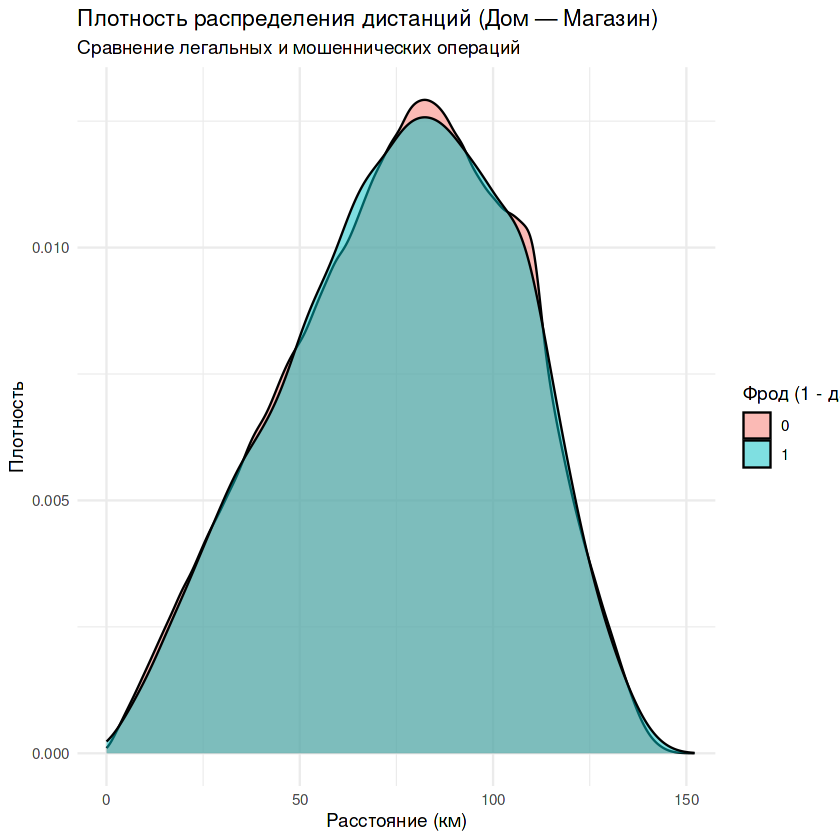

In [21]:
ggplot(df, aes(x = purchase_dist, fill = factor(is_fraud))) +
  geom_density(alpha = 0.5) +
  coord_cartesian(xlim = c(0, 150)) + 
  labs(
    title = "Плотность распределения дистанций (Дом — Магазин)",
    subtitle = "Сравнение легальных и мошеннических операций",
    x = "Расстояние (км)",
    y = "Плотность",
    fill = "Фрод (1 - да)"
  ) +
  theme_minimal()


In [22]:
check_counts <- df %>%
  group_by(state) %>%
  summarise(count = n()) %>%
  arrange(count)

small_categories <- check_counts %>% filter(count > 50)
print(small_categories)


# A tibble: 50 × 2
   state count
   <fct> <int>
 1 RI      641
 2 AK     2548
 3 HI     3129
 4 DC     4457
 5 NV     6993
 6 ID     6999
 7 CT     9537
 8 NH    10154
 9 AZ    13309
10 UT    13360
# ℹ 40 more rows


In [23]:
df_select <- df %>% select(merchant, category, amt, city_pop, age, month, day_of_week, purchase_dist, gender)
results <- list()
for (col_name in names(df_select)) {
  val <- mutinformation(discretize(df[[col_name]]), discretize(df$is_fraud))
  results[[col_name]] <- val
}

final_mi <- data.frame(
  column = names(results),
  mi = unlist(results)
)


In [24]:
df <- df %>%
  mutate(state = as.character(state)) %>%
  mutate(state = ifelse(state %in% c("DE", "RI", "AK"), "Other", state)) %>%
  mutate(state = as.factor(state)) # Возвращаем в фактор для MI/IV

length(unique(df$state)) 


[1] 49

In [25]:
features <- c("merchant", "category", "amt", "city_pop", "age", 
              "month", "day_of_week", "purchase_dist", "gender", "state", "hour")

iv_analysis <- create_infotables(data = df[, c(features, "is_fraud")], 
                                 y = "is_fraud", 
                                 parallel = TRUE)
iv_table <- iv_analysis$Summary
df_mi <- df %>% select(all_of(features))
for(col in names(df_mi)) {
  if(is.numeric(df_mi[[col]])) {
    df_mi[[col]] <- as.integer(discretize(df_mi[[col]], nbins = 20)[,1])
  } else {
    df_mi[[col]] <- as.integer(as.factor(df_mi[[col]]))
  }
}

mi_scores <- miScores(X = df_mi, Y = as.integer(df$is_fraud))
mi_table <- data.frame(
  Variable = names(mi_scores), 
  MI = as.numeric(mi_scores)
) %>% arrange(desc(MI))
final_importance <- iv_table %>%
  left_join(mi_table, by = "Variable") %>%
  arrange(desc(IV))
print(final_importance)


        Variable           IV           MI
1            amt 3.3002934364 1.027518e-02
2           hour 1.7225413122 4.510389e-03
3       merchant 0.8324633481 2.068471e-03
4       category 0.7487471783 1.882160e-03
5          month 0.0953104676 2.508467e-04
6            age 0.0508740173 1.464918e-04
7          state 0.0375376470 9.782743e-05
8    day_of_week 0.0273657812 6.877930e-05
9         gender 0.0064967870 1.644473e-05
10      city_pop 0.0055295475 2.285070e-05
11 purchase_dist 0.0005140231 4.271892e-06


In [26]:
desc_stats <- df %>%
  group_by(is_fraud) %>%
  summarise(
    n = n(),
    mean_amt = mean(amt),
    sd_amt = sd(amt),
    var_amt = var(amt),
    mean_dist = mean(purchase_dist, na.rm = TRUE),
    median_amt = median(amt)
  )
print(desc_stats)

# A tibble: 2 × 7
  is_fraud       n mean_amt sd_amt var_amt mean_dist median_amt
     <int>   <int>    <dbl>  <dbl>   <dbl>     <dbl>      <dbl>
1        0 1596143     67.6   153.  23492.      76.1       47.2
2        1    8151    530.    392. 153416.      76.2      385. 


In [27]:
t_test_result <- t.test(amt ~ is_fraud, data = df)
print(t_test_result)


	Welch Two Sample t-test

data:  amt by is_fraud
t = -106.53, df = 8162.8, p-value < 2.2e-16
alternative hypothesis: true difference in means between group 0 and group 1 is not equal to 0
95 percent confidence interval:
 -470.8748 -453.8595
sample estimates:
mean in group 0 mean in group 1 
       67.62292       529.99007 



In [28]:
contingency_table <- table(df$category, df$is_fraud)
chi_sq_result <- chisq.test(contingency_table)
print(chi_sq_result)


	Pearson's Chi-squared test

data:  contingency_table
X-squared = 7092.7, df = 13, p-value < 2.2e-16



In [29]:
model_data <- df %>%
  mutate(
    log_amt = log1p(amt),
    hour_sin = sin(2 * pi * hour / 24),
    hour_cos = cos(2 * pi * hour / 24),
    age = as.numeric(scale(age)),
    log_amt = as.numeric(scale(log_amt))
  ) %>%
  select(is_fraud, log_amt, category, hour_sin, hour_cos, age)
weight_0 <- 1 / (table(model_data$is_fraud)[1] / nrow(model_data))
weight_1 <- 1 / (table(model_data$is_fraud)[2] / nrow(model_data))
weights <- ifelse(model_data$is_fraud == 1, weight_1, weight_0)
logit_model <- glm(is_fraud ~ log_amt + category + hour_sin + hour_cos + age, 
                   data = model_data, 
                   weights = weights,
                   family = "binomial")
summary(logit_model)
exp(coef(logit_model))


Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”



Call:
glm(formula = is_fraud ~ log_amt + category + hour_sin + hour_cos + 
    age, family = "binomial", data = model_data, weights = weights)

Coefficients:
                        Estimate Std. Error  z value Pr(>|z|)    
(Intercept)            -2.885980   0.007850 -367.620  < 2e-16 ***
log_amt                 1.119426   0.001787  626.311  < 2e-16 ***
categoryfood_dining     0.415489   0.010247   40.549  < 2e-16 ***
categorygas_transport   2.212165   0.009265  238.777  < 2e-16 ***
categorygrocery_net     1.826569   0.011521  158.540  < 2e-16 ***
categorygrocery_pos     1.570614   0.008695  180.627  < 2e-16 ***
categoryhealth_fitness  0.840003   0.010441   80.455  < 2e-16 ***
categoryhome           -0.063698   0.009772   -6.518 7.11e-11 ***
categorykids_pets       1.061602   0.009514  111.577  < 2e-16 ***
categorymisc_net        1.442629   0.010021  143.959  < 2e-16 ***
categorymisc_pos        1.795259   0.010358  173.321  < 2e-16 ***
categorypersonal_care   1.264775   0.009806  128.

(Intercept)                log_amt    categoryfood_dining 
             0.0558001              3.0630949              1.5151121 
 categorygas_transport    categorygrocery_net    categorygrocery_pos 
             9.1354729              6.2125324              4.8096005 
categoryhealth_fitness           categoryhome      categorykids_pets 
             2.3163741              0.9382886              2.8909978 
      categorymisc_net       categorymisc_pos  categorypersonal_care 
             4.2318060              6.0210317              3.5422965 
  categoryshopping_net   categoryshopping_pos         categorytravel 
             4.6430711              2.5699157             11.6290641 
              hour_sin               hour_cos                    age 
             0.6719928              5.6622831              1.0626425

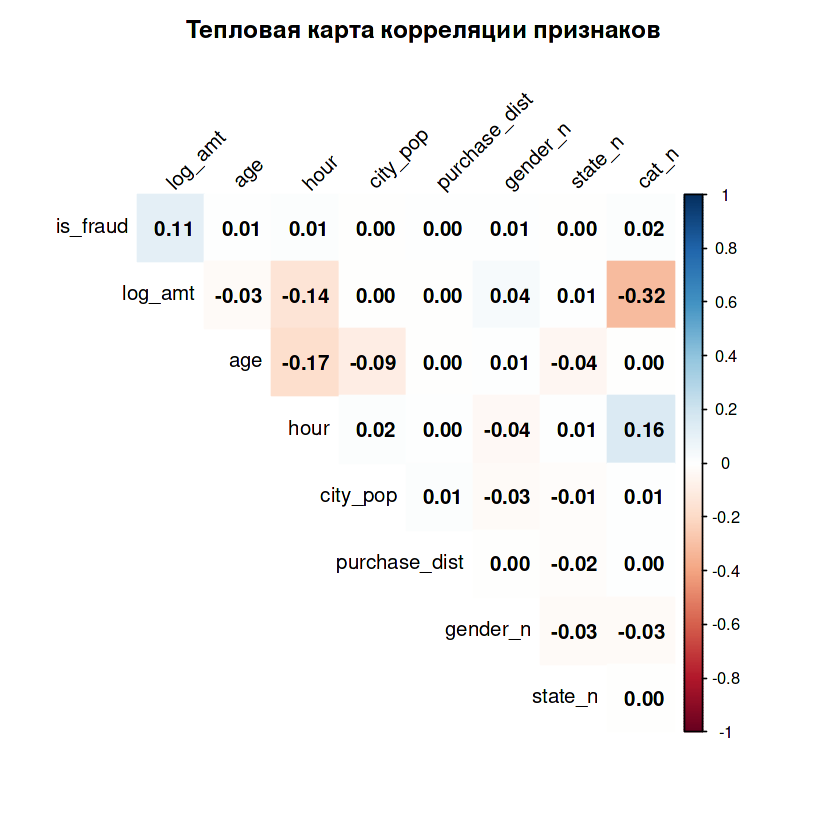

In [30]:
cor_data <- df %>%
  mutate(
    gender_n = as.numeric(as.factor(gender)),
    state_n = as.numeric(as.factor(state)),
    cat_n = as.numeric(as.factor(category)),
    log_amt = log1p(amt)
  ) %>%
  select(is_fraud, log_amt, age, hour, city_pop, purchase_dist, gender_n, state_n, cat_n)
M <- cor(cor_data, use = "complete.obs")
corrplot(M, 
         method = "color",
         type = "upper",
         addCoef.col = "black",
         tl.col = "black",
         tl.srt = 45,
         diag = FALSE,
         title = "\n\n Тепловая карта корреляции признаков",
         sig.level = 0.05, insig = "blank"
)

In [31]:
model_data <- df %>%
  mutate(
    log_amt = log1p(amt),
    hour_sin = sin(2 * pi * hour / 24),
    hour_cos = cos(2 * pi * hour / 24),
    age = as.numeric(scale(age)),
    log_amt = as.numeric(scale(log_amt))
  ) %>%
  select(is_fraud, log_amt, category, hour_sin, hour_cos, age)
features_matrix <- model.matrix(is_fraud ~ . -1, data = model_data)
target <- as.matrix(model_data$is_fraud)
set.seed(42)
index <- sample(1:nrow(features_matrix), 0.8 * nrow(features_matrix))

x_train <- features_matrix[index, ]
y_train <- target[index, ]
x_test  <- features_matrix[-index, ]
y_test  <- target[-index, ]

model <- keras_model_sequential() %>%
  layer_dense(units = 64, activation = 'relu', input_shape = ncol(x_train)) %>%
  layer_dropout(rate = 0.2) %>% 
  layer_dense(units = 32, activation = 'relu') %>%
  layer_dropout(rate = 0.2) %>%
  layer_dense(units = 1, activation = 'sigmoid')

model %>% compile(
  loss = 'binary_crossentropy',
  optimizer = optimizer_adam(learning_rate = 0.001),
  metrics = c('accuracy', 'AUC')
)

counts <- table(y_train)
class_weights <- list("0" = 1, "1" = as.numeric(counts["0"] / counts["1"]))
history <- model %>% fit(
  x_train, y_train,
  epochs = 20,
  batch_size = 512,
  validation_split = 0.2,
  class_weight = class_weights,
  verbose = 1
)
results <- model %>% evaluate(x_test, y_test)
print(results)

     loss  accuracy       auc 
0.0672985 0.9735398 0.9970136 


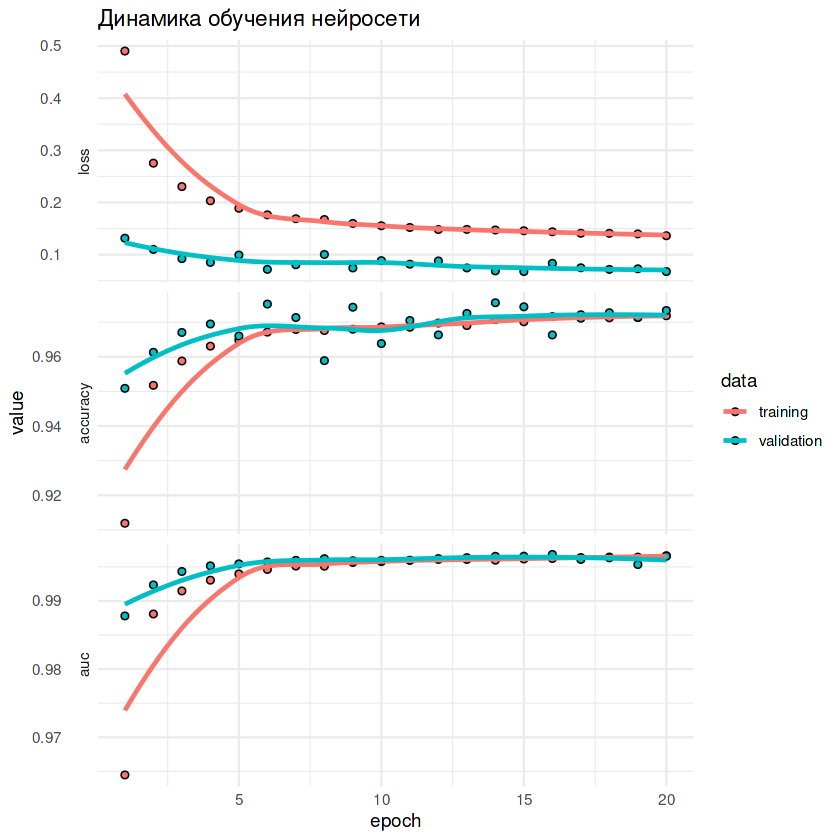

In [32]:
plot(history) + 
  theme_minimal() + 
  labs(title = "Динамика обучения нейросети")


Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var


Setting levels: control = 0, case = 1

Warning message in roc.default(y_test, predictions):
“Deprecated use a matrix as predictor. Unexpected results may be produced, please pass a numeric vector.”
Setting direction: controls < cases



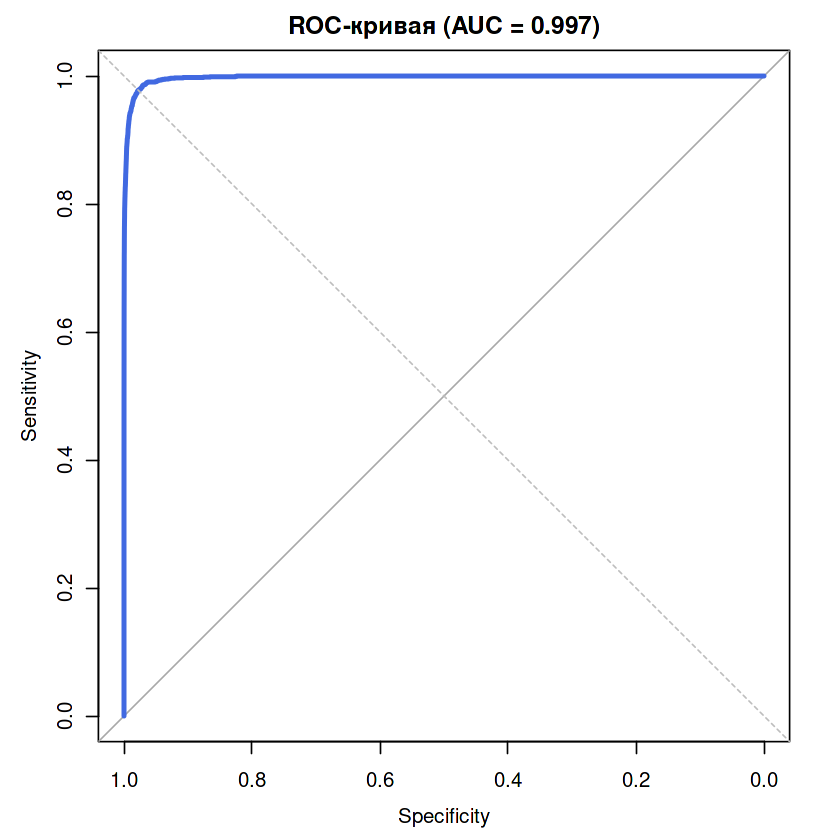

In [33]:
predictions <- model %>% predict(x_test)
roc_obj <- roc(y_test, predictions)
plot(roc_obj, col = "royalblue", lwd = 3, main = "ROC-кривая (AUC = 0.997)")
abline(a = 0, b = 1, lty = 2, col = "grey")

In [34]:
y_pred_class <- ifelse(predictions > 0.5, 1, 0)
table_mat <- table(Actual = y_test, Predicted = y_pred_class)
print(table_mat)

      Predicted
Actual      0      1
     0 310700   8457
     1     33   1669
